# Прогноз урожайности дикой черники

## Постановка задачи

Нужно предсказать урожайность `yield` по характеристикам участка, погоде и плотности опылителей. Поскольку результат выражен числом в кг/га, это задача регрессии.

В учебном сценарии прогноз делается **в конце цветения, до сбора урожая**. К этому моменту считаем известными погодные итоги периода цветения, размер клона и плотности опылителей. Для реального прогноза доступность этих измерений нужно подтвердить. Показатели формирования плодов `fruitset`, `fruitmass` и `seeds` исключаем из входов.

Датасет получен с помощью [модели опыления дикой черники](https://data.mendeley.com/datasets/p5hvjzsvn8/1). Исследуем качество данных, связи признаков с урожайностью и сравним несколько вариантов линейной регрессии с прогнозом среднего.

## Описание данных

В исходном файле **777 строк и 18 столбцов**; ниже исследуются только 621 обучающая строка. Строка описывает один смоделированный сценарий: сочетание характеристик участка, опылителей и погоды вместе с полученным результатом. Авторы исследования указывают, что результат для сценария получен усреднением 100 запусков симуляции. 

| Столбец | Что означает | Единица или роль |
|---|---|---|
| `Row#` | Порядковый номер строки | Идентификатор, не используем как признак модели |
| `clonesize` | Средний размер клона черники на участке | м²; клон — группа генетически одинаковых растений |
| `honeybee` | Плотность медоносных пчёл | пчёл / м² / мин |
| `bumbles` | Плотность шмелей | пчёл / м² / мин |
| `andrena` | Плотность пчёл рода Andrena | пчёл / м² / мин |
| `osmia` | Плотность пчёл рода Osmia | пчёл / м² / мин |
| `MaxOfUpperTRange` | Наибольшее из дневных максимумов температуры за период цветения | °F |
| `MinOfUpperTRange` | Наименьшее из дневных максимумов температуры за период цветения | °F |
| `AverageOfUpperTRange` | Среднее дневных максимумов температуры за период цветения | °F |
| `MaxOfLowerTRange` | Наибольшее из дневных минимумов температуры за период цветения | °F |
| `MinOfLowerTRange` | Наименьшее из дневных минимумов температуры за период цветения | °F |
| `AverageOfLowerTRange` | Среднее дневных минимумов температуры за период цветения | °F |
| `RainingDays` | Количество дней с осадками за период цветения | дней |
| `AverageRainingDays` | Усреднённый показатель дождливых дней за период цветения | Точное определение и единицу требуется уточнить |
| `fruitset` | Показатель завязывания плодов: какая доля цветков превратилась в плоды | Доля |
| `fruitmass` | Показатель массы плодов | Точное определение и единицу требуется уточнить |
| `seeds` | Показатель количества семян в плодах | Точное определение требуется уточнить |
| `yield` | Смоделированная урожайность | **кг/га; целевой признак** |

В исходном CSV температура указана в градусах Фаренгейта; ниже мы переведём её в Цельсии: например, 86 °F = 30 °C. `yield` — урожайность на гектар, а не просто общая масса урожая участка.

`fruitset`, `fruitmass` и `seeds` являются результатами формирования плодов. Доступны ли они в момент предполагаемого прогноза, нужно согласовать; поэтому в первой модели мы их не используем. Для `AverageRainingDays` источники описывают усреднение неоднозначно, поэтому не будем пока считать его конкретной долей или количеством дней.

Источники: [публикация авторов модели и таблица признаков](https://doi.org/10.1016/j.compag.2020.105778), [описание завязывания плодов](https://www.mdpi.com/2073-4395/11/9/1736), [набор данных Mendeley](https://data.mendeley.com/datasets/p5hvjzsvn8/1).

## Установка зависимостей

Для первого запуска создайте виртуальное окружение Python 3.12 в папке проекта и установите зависимости:

```bash
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
```

В Windows вместо `source .venv/bin/activate` используйте `.venv\Scripts\activate` в командной строке или `.venv\Scripts\Activate.ps1` в PowerShell. Откройте ноутбук в VS Code или Jupyter и выберите интерпретатор из `.venv` как ядро. Ячейку ниже можно выполнить для установки зависимостей в выбранное ядро; после установки при необходимости перезапустите его.

In [1]:
%pip install -r requirements.txt

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from scipy.stats import loguniform
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Первичный осмотр

В исследовании используются 621 обучающий сценарий; ещё 156 строк отложены. `Row#` содержит идентификатор записи, `yield` — целевую урожайность.

### Разделение данных

Из 777 строк 621 выделена для исследования и обучения, 156 — отложена. Все расчёты и сравнения ниже выполнены на обучающей части; отложенная часть не используется. Для независимой финальной оценки нужны ранее не изученные данные, а для проверки применимости к реальным хозяйствам — полевые данные.

На этих же 156 строках уже считалась тестовая метрика в ранней версии. В текущем сравнении они остаются в резерве.

In [3]:
all_data = pd.read_csv(Path("WildBlueberryPollinationSimulationData.csv"))
# Откладываем 20% строк до изучения содержимого и любых преобразований.
df_raw, reserved_data = train_test_split(all_data, test_size=0.2, random_state=42)
df = df_raw.copy()
print(
    f"Всего строк: {len(all_data)}; для исследования и обучения: {len(df)}; отложено: {len(reserved_data)}"
)
print(f"Столбцов: {df.shape[1]}")
df.head()

Всего строк: 777; для исследования и обучения: 621; отложено: 156
Столбцов: 18


,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
739,739,25.0,0.50,0.38,0.50,0.75,69.7,42.1,58.2,50.2,24.3,41.2,16.0,0.26,0.498716,0.431072,35.184412,6034.642135
133,133,12.5,0.25,0.25,0.38,0.25,94.6,57.2,79.0,68.2,33.0,55.9,16.0,0.26,0.500438,0.444588,35.384612,5643.360448
234,234,12.5,0.25,0.25,0.50,0.63,94.6,57.2,79.0,68.2,33.0,55.9,34.0,0.56,0.404446,0.401091,30.665221,4100.759169
55,55,12.5,0.25,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,24.0,0.39,0.466974,0.429452,33.669875,4999.156215
639,639,25.0,0.50,0.25,0.75,0.75,94.6,57.2,79.0,68.2,33.0,55.9,24.0,0.39,0.403217,0.404869,31.231910,4218.327986


### Перевод температуры в градусы Цельсия

Температурные признаки исходного файла переведены из °F в °C по формуле `(°F − 32) × 5 / 9`. Исходный CSV и таблица `df_raw` сохранены без изменений; дальнейший анализ выполняется на копии `df`.

In [4]:
temperature_columns = [
    "MaxOfUpperTRange",
    "MinOfUpperTRange",
    "AverageOfUpperTRange",
    "MaxOfLowerTRange",
    "MinOfLowerTRange",
    "AverageOfLowerTRange",
]

df = df_raw.copy()
df[temperature_columns] = (df_raw[temperature_columns] - 32) * 5 / 9

# Сравним значения до и после перевода на примере первой строки.
comparison = pd.DataFrame(
    {
        "В исходном файле, °F": df_raw.loc[df_raw.index[0], temperature_columns],
        "После перевода, °C": df.loc[df.index[0], temperature_columns],
    }
)
comparison.round(2)

,"В исходном файле, °F","После перевода, °C"
MaxOfUpperTRange,69.7,20.94
MinOfUpperTRange,42.1,5.61
AverageOfUpperTRange,58.2,14.56
MaxOfLowerTRange,50.2,10.11
MinOfLowerTRange,24.3,-4.28
AverageOfLowerTRange,41.2,5.11


### Оптимизация памяти

В рабочей таблице уменьшены типы `Row#` и `clonesize`. Перед преобразованием `clonesize` проверено, что значения не изменятся. Температуры и остальные дробные показатели сохранены с исходной точностью.

In [5]:
memory_before = df.memory_usage(deep=True).sum()
optimized = df.copy()

# Номер строки: pandas выбирает целочисленный тип с учётом диапазона.
optimized["Row#"] = pd.to_numeric(df["Row#"], downcast="integer")

# Применяем float32 только когда ни одно значение не изменилось.
clone_float32 = df["clonesize"].astype("float32")
if np.array_equal(
    df["clonesize"].to_numpy(),
    clone_float32.astype("float64").to_numpy(),
    equal_nan=True,
):
    optimized["clonesize"] = clone_float32

# Проверяем, что каждое значение осталось тем же.
assert all(
    np.array_equal(df[column].to_numpy(), optimized[column].to_numpy(), equal_nan=True)
    for column in df.columns
), "При преобразовании изменились значения"

memory_after = optimized.memory_usage(deep=True).sum()
print(f"Память до: {memory_before:,} байт; после: {memory_after:,} байт")
print(
    f"Экономия: {memory_before - memory_after:,} байт ({(memory_before - memory_after) / memory_before * 100:.2f}%)"
)
print("Типы изменённых столбцов:")
print(
    pd.DataFrame(
        {"До": df.dtypes.astype(str), "После": optimized.dtypes.astype(str)}
    ).query("До != После")
)

df = optimized

Память до: 110,944 байт; после: 104,734 байт
Экономия: 6,210 байт (5.60%)
Типы изменённых столбцов:
                До    После
Row#         int64    int16
clonesize  float64  float32


In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 621 entries, 739 to 102
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row#                  621 non-null    int16  
 1   clonesize             621 non-null    float32
 2   honeybee              621 non-null    float64
 3   bumbles               621 non-null    float64
 4   andrena               621 non-null    float64
 5   osmia                 621 non-null    float64
 6   MaxOfUpperTRange      621 non-null    float64
 7   MinOfUpperTRange      621 non-null    float64
 8   AverageOfUpperTRange  621 non-null    float64
 9   MaxOfLowerTRange      621 non-null    float64
 10  MinOfLowerTRange      621 non-null    float64
 11  AverageOfLowerTRange  621 non-null    float64
 12  RainingDays           621 non-null    float64
 13  AverageRainingDays    621 non-null    float64
 14  fruitset              621 non-null    float64
 15  fruitmass             621 non-null   

## 2. Качество данных

Проверены типы, пропуски, полные дубликаты без идентификатора и потенциальные выбросы по правилу межквартильного размаха (IQR).

In [7]:
print("Пропуски:")
print(df.isna().sum().to_string())
print("\nПолные дубликаты без Row#:", df.drop(columns="Row#").duplicated().sum())
print("Повторы Row#:", df["Row#"].duplicated().sum())
print("\nРазличных значений:")
print(df.nunique().to_string())

Пропуски:
Row#                    0
clonesize               0
honeybee                0
bumbles                 0
andrena                 0
osmia                   0
MaxOfUpperTRange        0
MinOfUpperTRange        0
AverageOfUpperTRange    0
MaxOfLowerTRange        0
MinOfLowerTRange        0
AverageOfLowerTRange    0
RainingDays             0
AverageRainingDays      0
fruitset                0
fruitmass               0
seeds                   0
yield                   0

Полные дубликаты без Row#: 0
Повторы Row#: 0

Различных значений:
Row#                    621
clonesize                 4
honeybee                  7
bumbles                   7
andrena                  11
osmia                    10
MaxOfUpperTRange          5
MinOfUpperTRange          5
AverageOfUpperTRange      5
MaxOfLowerTRange          5
MinOfLowerTRange          5
AverageOfLowerTRange      5
RainingDays               5
AverageRainingDays        5
fruitset                621
fruitmass               621
seeds  

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Row#,621.0,383.996779,222.989990,0.000000,189.000000,380.000000,574.000000,776.000000
clonesize,621.0,18.611111,7.001824,12.500000,12.500000,12.500000,25.000000,37.500000
honeybee,621.0,0.418396,1.063678,0.000000,0.250000,0.250000,0.500000,18.430000
bumbles,621.0,0.284332,0.065624,0.000000,0.250000,0.250000,0.380000,0.380000
andrena,621.0,0.467902,0.159119,0.000000,0.380000,0.500000,0.630000,0.750000
osmia,621.0,0.564686,0.165445,0.000000,0.500000,0.630000,0.750000,0.750000
MaxOfUpperTRange,621.0,27.958311,5.156556,20.944444,25.222222,30.000000,34.777778,34.777778
MinOfUpperTRange,621.0,9.857577,3.133678,3.888889,8.222222,11.111111,14.000000,14.000000
AverageOfUpperTRange,621.0,20.428073,4.306358,14.555556,18.166667,22.166667,26.111111,26.111111
MaxOfLowerTRange,621.0,15.190016,3.727624,10.111111,13.222222,16.666667,20.111111,20.111111


In [9]:
q1 = df["yield"].quantile(0.25)
q3 = df["yield"].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Границы IQR для yield: {lower:.1f} ... {upper:.1f}")
print("Значения за границами:", ((df["yield"] < lower) | (df["yield"] > upper)).sum())

Границы IQR для yield: 2271.0 ... 9952.0
Значения за границами: 2


В обучающей части пропусков и полных дубликатов без `Row#` не обнаружено. Для `yield` правило IQR выделяет два потенциально необычных значения; данные не изменялись, поскольку нет оснований считать их ошибочными. Небольшое число различных значений климатических признаков согласуется с использованием сценариев симуляции.

## 3. Распределение урожайности

В обучающей части медианная урожайность составляет около 6 156 кг/га; 50% значений находятся примерно между 5 151 и 7 072 кг/га. Минимум — 1 638, максимум — 8 744 кг/га.

count     621.000000
mean     6048.995491
std      1345.016575
min      1637.704022
25%      5151.386473
50%      6155.896087
75%      7071.615319
max      8743.520983
Name: yield, dtype: float64


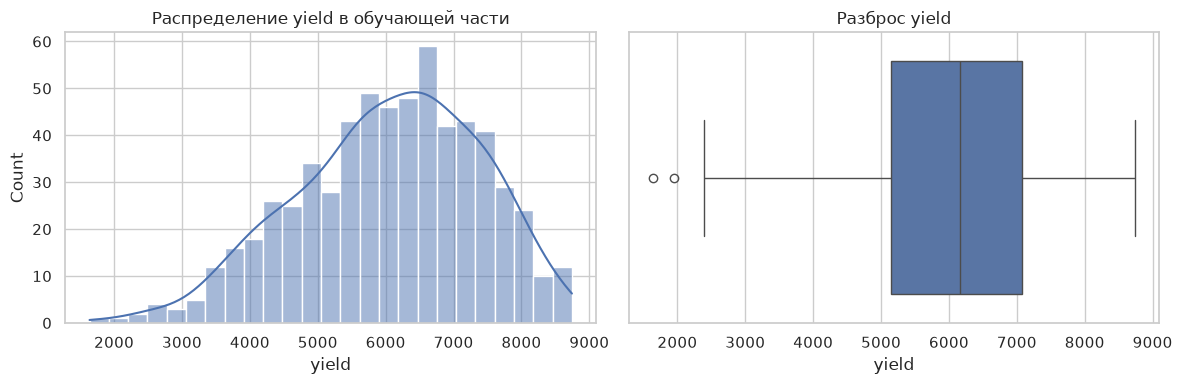

In [10]:
print(df["yield"].describe())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="yield", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Распределение yield в обучающей части")
sns.boxplot(data=df, x="yield", ax=axes[1])
axes[1].set_title("Разброс yield")
plt.tight_layout()
plt.show()

### 3.1. Распределения признаков

В обучающей части `clonesize` принимает 4 разных значения, `RainingDays` — 5. Это ограничивает разнообразие сценариев, на которых обучается модель.

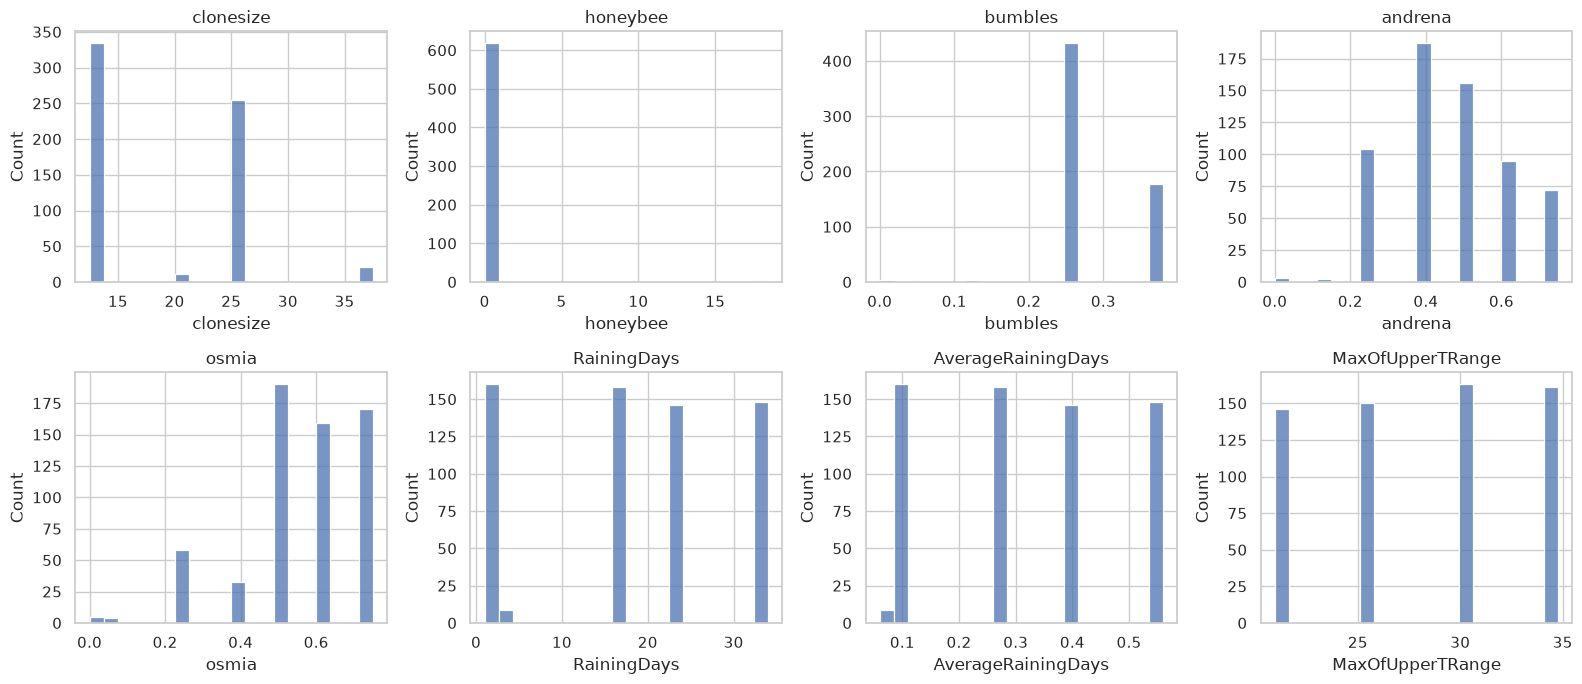

,min,median,max,nunique
clonesize,12.50,12.50,37.50,4.0
honeybee,0.00,0.25,18.43,7.0
bumbles,0.00,0.25,0.38,7.0
andrena,0.00,0.50,0.75,11.0
osmia,0.00,0.63,0.75,10.0
RainingDays,1.00,16.00,34.00,5.0
AverageRainingDays,0.06,0.26,0.56,5.0
MaxOfUpperTRange,20.94,30.00,34.78,5.0


In [11]:
eda_columns = [
    "clonesize",
    "honeybee",
    "bumbles",
    "andrena",
    "osmia",
    "RainingDays",
    "AverageRainingDays",
    "MaxOfUpperTRange",
]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for column, ax in zip(eda_columns, axes.flat):
    sns.histplot(data=df, x=column, bins=20, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

df[eda_columns].agg(["min", "median", "max", "nunique"]).T.round(2)

### 3.2. Проверка необычных значений

Проверим неотрицательность плотностей, массы, числа семян и урожайности, а также диапазон `fruitset`. Для поиска необычных значений используем правило IQR.

In [12]:
nonnegative_columns = [
    "clonesize",
    "honeybee",
    "bumbles",
    "andrena",
    "osmia",
    "RainingDays",
    "AverageRainingDays",
    "fruitmass",
    "seeds",
    "yield",
]
print("Количество отрицательных значений:")
print((df[nonnegative_columns] < 0).sum().to_string())
print(
    "Значения fruitset вне диапазона от 0 до 1:", (~df["fruitset"].between(0, 1)).sum()
)

examined = df.drop(columns="Row#")
q1 = examined.quantile(0.25)
q3 = examined.quantile(0.75)
iqr = q3 - q1
outliers = ((examined < q1 - 1.5 * iqr) | (examined > q3 + 1.5 * iqr)).sum()
pd.DataFrame(
    {
        "Нижняя граница IQR": q1 - 1.5 * iqr,
        "Верхняя граница IQR": q3 + 1.5 * iqr,
        "Число кандидатов": outliers,
        "Уникальных значений": examined.nunique(),
    }
).round(2)

Количество отрицательных значений:
clonesize             0
honeybee              0
bumbles               0
andrena               0
osmia                 0
RainingDays           0
AverageRainingDays    0
fruitmass             0
seeds                 0
yield                 0
Значения fruitset вне диапазона от 0 до 1: 0


,Нижняя граница IQR,Верхняя граница IQR,Число кандидатов,Уникальных значений
clonesize,-6.25,43.75,0,4
honeybee,-0.12,0.88,3,7
bumbles,0.05,0.57,6,7
andrena,0.01,1.00,3,11
osmia,0.12,1.12,10,10
MaxOfUpperTRange,10.89,49.11,0,5
MinOfUpperTRange,-0.44,22.67,0,5
AverageOfUpperTRange,6.25,38.03,0,5
MaxOfLowerTRange,2.89,30.44,0,5
MinOfLowerTRange,-7.78,5.56,0,5


Отрицательных значений у проверенных показателей и `fruitset` за пределами [0; 1] не обнаружено. Значения, отмеченные правилом IQR, оставлены в данных: оснований считать их ошибочными нет.

## 4. Связи признаков и урожайности

Для числовых признаков рассчитана корреляция Пирсона и построены графики зависимости от `yield`. Показатели формирования плодов представлены в EDA, но исключены из первой модели из-за неопределённости их доступности к концу цветения.

In [13]:
numeric = df.drop(columns="Row#")
corr = numeric.corr(numeric_only=True)
corr["yield"].sort_values(ascending=False).to_frame("Корреляция с yield")

,Корреляция с yield
yield,1.000000
fruitset,0.983582
seeds,0.959927
fruitmass,0.927421
osmia,0.392481
bumbles,0.306248
andrena,0.166286
honeybee,-0.035640
MinOfUpperTRange,-0.184813
AverageOfLowerTRange,-0.188305


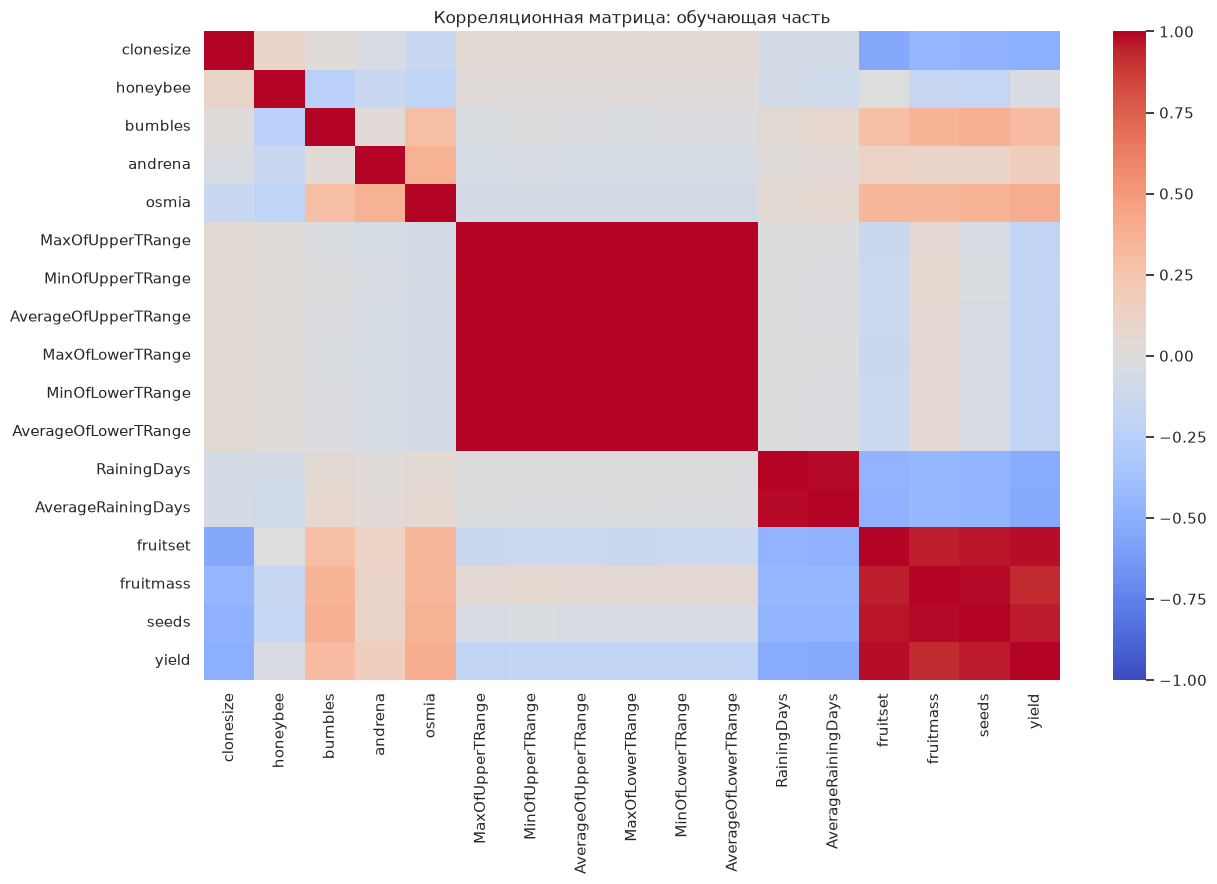

In [14]:
fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Корреляционная матрица: обучающая часть")
plt.tight_layout()
plt.show()

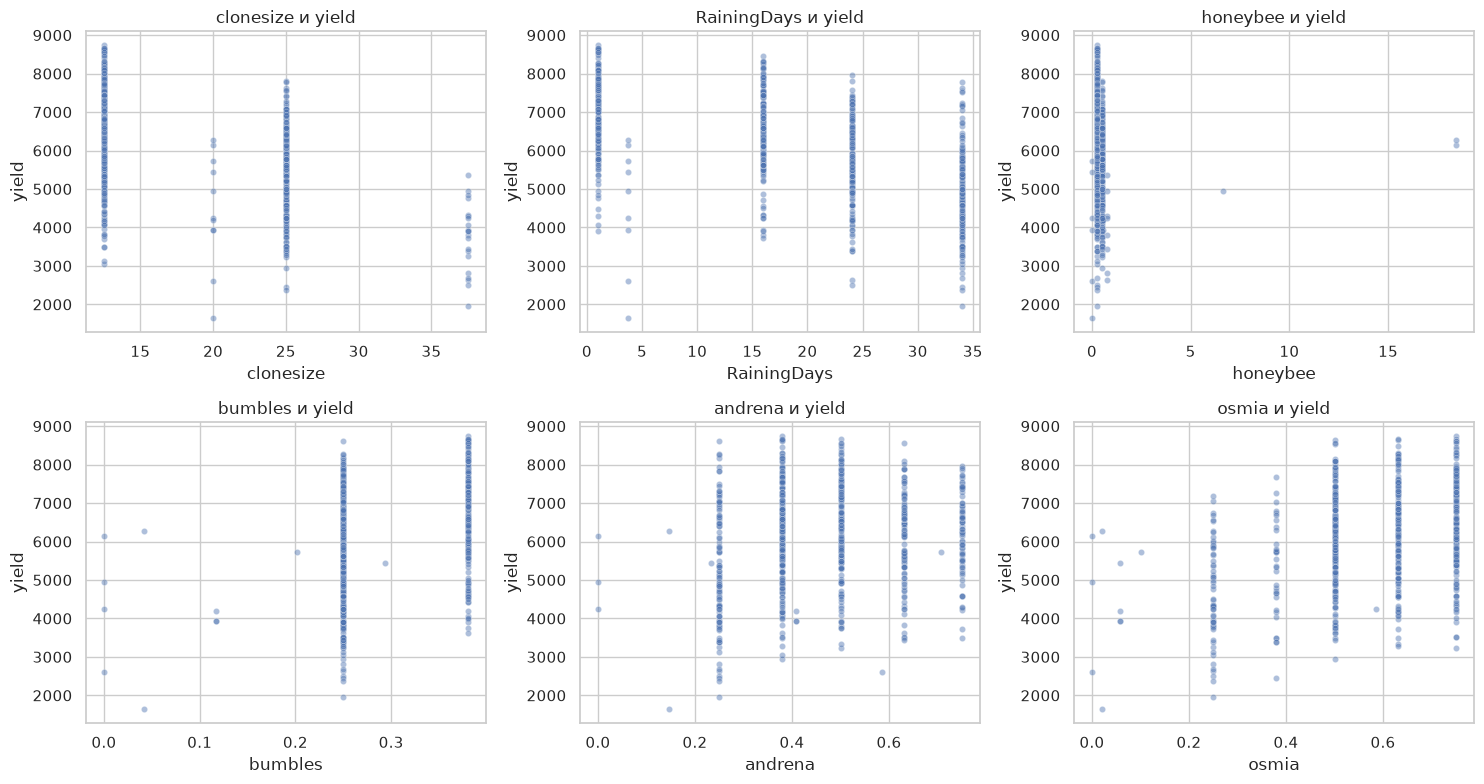

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, ax in zip(
    ["clonesize", "RainingDays", "honeybee", "bumbles", "andrena", "osmia"], axes.flat
):
    sns.scatterplot(data=df, x=column, y="yield", alpha=0.45, s=20, ax=ax)
    ax.set_title(f"{column} и yield")
plt.tight_layout()
plt.show()

### 4.1. Урожайность и дождливые дни

Для сценариев с разным `RainingDays` рассчитаны количество наблюдений, средняя и медианная урожайность.

,наблюдений,среднее,медиана,минимум,максимум
RainingDays,,,,,
1.00,160,6943.1,7006.4,3900.3,8743.5
3.77,9,4548.2,4936.4,1637.7,6276.4
16.00,158,6578.6,6591.7,3720.7,8465.9
24.00,146,5728.4,5748.5,2508.4,7969.0
34.00,148,4924.5,4878.4,1945.5,7778.3


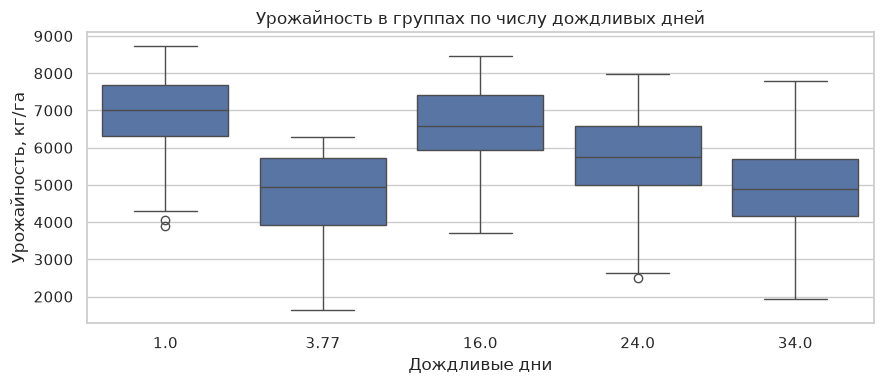

In [16]:
rain_groups = df.groupby("RainingDays")["yield"].agg(
    наблюдений="size", среднее="mean", медиана="median", минимум="min", максимум="max"
)
display(rain_groups.round(1))
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x="RainingDays", y="yield", ax=ax)
ax.set(
    title="Урожайность в группах по числу дождливых дней",
    xlabel="Дождливые дни",
    ylabel="Урожайность, кг/га",
)
plt.tight_layout()
plt.show()

В сценариях с 1 дождливым днём средняя урожайность составляет около 6 943 кг/га, с 34 днями — 4 925 кг/га. Остальные условия сценариев тоже могут различаться, поэтому по этому сравнению нельзя оценить отдельное влияние дождя. Значение `RainingDays = 3,77` требует уточнения у источника данных.

### 4.2. Связанность погодных признаков

Сравним оставленные в модели на семи признаках погодные показатели с теми, которые из неё исключены. Корреляции рассчитаны на обучающей части.

In [17]:
weather_pairs = [
    ("MaxOfUpperTRange", "MinOfUpperTRange"),
    ("MaxOfUpperTRange", "AverageOfUpperTRange"),
    ("MaxOfUpperTRange", "MaxOfLowerTRange"),
    ("MaxOfUpperTRange", "MinOfLowerTRange"),
    ("MaxOfUpperTRange", "AverageOfLowerTRange"),
    ("RainingDays", "AverageRainingDays"),
]
weather_correlations = pd.DataFrame(
    [
        {
            "Оставлен в модели на 7 признаках": kept,
            "Исключён из модели на 7 признаках": removed,
            "Корреляция Пирсона": df[kept].corr(df[removed]),
        }
        for kept, removed in weather_pairs
    ]
)
weather_correlations.round({"Корреляция Пирсона": 4})

,Оставлен в модели на 7 признаках,Исключён из модели на 7 признаках,Корреляция Пирсона
0,MaxOfUpperTRange,MinOfUpperTRange,0.9944
1,MaxOfUpperTRange,AverageOfUpperTRange,0.9990
2,MaxOfUpperTRange,MaxOfLowerTRange,0.9999
3,MaxOfUpperTRange,MinOfLowerTRange,0.9993
4,MaxOfUpperTRange,AverageOfLowerTRange,0.9986
5,RainingDays,AverageRainingDays,0.9916


Корреляция рассмотренных температурных пар составляет от 0,994 до 0,9999; корреляция двух показателей дождливости — 0,9916. Признаки тесно связаны, что может сделать коэффициенты линейной модели нестабильными. Проверим, как сокращение этих признаков влияет на качество линейной регрессии.

### Выводы по EDA

Корреляция с `yield` составляет −0,53 для `RainingDays`, −0,50 для `clonesize` и +0,39 для `osmia`. Показатели `fruitset`, `fruitmass` и `seeds` связаны с целью сильнее, но для прогноза к концу цветения они могут быть недоступны. Эти связи описывают сценарии симуляции и сами по себе не доказывают причину изменения урожая.

### Стратегия предобработки

В рабочей выборке нет пропусков, все выбранные входы числовые. Заполнение пропусков
и кодирование категорий здесь не нужны. `Row#` исключаем как идентификатор,
`yield` остаётся целью, показатели формирования плодов используем только в EDA.
Переводим температуры из °F в °C, чтобы читать и проверять значения в привычных единицах.
Для регуляризации применяем `StandardScaler`, чтобы штраф за коэффициенты не зависел
от разницы масштабов входных признаков.

## 5. Линейная регрессия

Исключим `Row#`, целевой `yield` и характеристики сформировавшихся плодов. В качестве базового прогноза возьмём среднюю урожайность обучающей части. Модели сравниваются на пяти разбиениях кросс-валидации. `StandardScaler` находится внутри `Pipeline`, поэтому его параметры рассчитываются отдельно на обучающей части каждого разбиения.

In [18]:
train_df = df.copy()
excluded = ["Row#", "yield", "fruitset", "fruitmass", "seeds"]
feature_names = [column for column in train_df.columns if column not in excluded]
X_train, y_train = train_df[feature_names], train_df["yield"]
print("Признаки модели:", ", ".join(feature_names))

Признаки модели: clonesize, honeybee, bumbles, andrena, osmia, MaxOfUpperTRange, MinOfUpperTRange, AverageOfUpperTRange, MaxOfLowerTRange, MinOfLowerTRange, AverageOfLowerTRange, RainingDays, AverageRainingDays


### Выбор метрик

Основная метрика — MAE: она показывает средний абсолютный промах в кг/га. Дополнительно используем MSE и RMSE, которые сильнее реагируют на большие ошибки, и R² — для сравнения с прогнозом среднего на оцениваемой части.

В таблицах приведены средние метрики по пяти блокам. Средняя RMSE не обязательно равна корню из средней MSE. Допустимый для хозяйства размер ошибки пока не задан.

In [19]:
models = {
    "Среднее (baseline)": DummyRegressor(strategy="mean"),
    "Линейная регрессия": make_pipeline(StandardScaler(), LinearRegression()),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
fold_rows = []
for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2",
        },
    )
    fold_mae = -scores["test_mae"]
    fold_mse = -scores["test_mse"]
    fold_rmse = np.sqrt(fold_mse)
    fold_r2 = scores["test_r2"]
    for fold, (mae, mse, rmse, r2) in enumerate(
        zip(fold_mae, fold_mse, fold_rmse, fold_r2), start=1
    ):
        fold_rows.append(
            {
                "Модель": name,
                "Разбиение": fold,
                "MAE": mae,
                "MSE": mse,
                "RMSE": rmse,
                "R²": r2,
            }
        )
    cv_rows.append(
        {
            "Модель": name,
            "MAE: среднее CV": fold_mae.mean(),
            "MAE: разброс CV": fold_mae.std(),
            "MSE: среднее CV": fold_mse.mean(),
            "RMSE: среднее CV": fold_rmse.mean(),
            "R²: среднее CV": fold_r2.mean(),
        }
    )
cv_results = pd.DataFrame(cv_rows).set_index("Модель")
cv_results.round(2)

,MAE: среднее CV,MAE: разброс CV,MSE: среднее CV,RMSE: среднее CV,R²: среднее CV
Модель,,,,,
Среднее (baseline),1099.43,63.40,1823403.41,1347.12,-0.03
Линейная регрессия,536.98,371.57,21261423.94,2402.22,-9.90


Средняя MAE полной модели ниже, чем у baseline: 537 против 1 099 кг/га. При этом средняя RMSE выше: 2 402 против 1 347 кг/га. Посмотрим результаты по отдельным блокам: крупная ошибка влияет на эти метрики по-разному.

### Качество на отдельных разбиениях

Метрики кросс-валидации рассчитаны отдельно для каждого из пяти разбиений обучающей части.

In [20]:
fold_results = pd.DataFrame(fold_rows).set_index(["Модель", "Разбиение"])
fold_results.round(2)

MAE           MSE      RMSE     R²
Модель             Разбиение                                        
Среднее (baseline) 1           994.35  1.545808e+06   1243.31  -0.00
                   2          1108.93  1.741808e+06   1319.78  -0.00
                   3          1120.41  1.953110e+06   1397.54  -0.00
                   4          1190.32  2.254607e+06   1501.53  -0.05
                   5          1083.12  1.621684e+06   1273.45  -0.08
Линейная регрессия 1           370.31  1.954439e+05    442.09   0.87
                   2           329.95  1.693235e+05    411.49   0.90
                   3          1279.65  1.055516e+08  10273.83 -53.04
                   4           357.93  2.060093e+05    453.88   0.90
                   5           347.06  1.847285e+05    429.80   0.88

В третьем блоке MAE полной модели составляет 1 280 кг/га, а R² — около −53. В остальных блоках MAE находится в диапазоне 330–370 кг/га. Разберём крупную ошибку отдельно.

### 5.1. Анализ нестабильного разбиения

На третьем разбиении обучающей части изучены строки с наибольшими ошибками и ранг матрицы признаков.

In [21]:
splits = list(cv.split(X_train, y_train))
fit_idx, valid_idx = splits[2]
fold_X_train, fold_X_valid = X_train.iloc[fit_idx], X_train.iloc[valid_idx]
fold_y_train, fold_y_valid = y_train.iloc[fit_idx], y_train.iloc[valid_idx]
fold_model = clone(models["Линейная регрессия"])
fold_model.fit(fold_X_train, fold_y_train)
fold_pred = fold_model.predict(fold_X_valid)

fold_errors = pd.DataFrame(
    {
        "Row#": train_df.iloc[valid_idx]["Row#"].to_numpy(),
        "Факт": fold_y_valid.to_numpy(),
        "Прогноз": fold_pred,
    }
)
fold_errors["Абсолютная ошибка"] = (fold_errors["Факт"] - fold_errors["Прогноз"]).abs()
fold_errors = fold_errors.sort_values("Абсолютная ошибка", ascending=False)
print("MAE всего блока:", round(fold_errors["Абсолютная ошибка"].mean(), 2))
print(
    "MAE без строки с наибольшей ошибкой (диагностика):",
    round(fold_errors["Абсолютная ошибка"].iloc[1:].mean(), 2),
)
print(
    "Ранг матрицы признаков:",
    fold_model.named_steps["linearregression"].rank_,
    "из",
    len(feature_names),
)
fold_errors.head(5).round(2)

MAE всего блока: 1279.65
MAE без строки с наибольшей ошибкой (диагностика): 361.04
Ранг матрицы признаков: 10 из 13


,Row#,Факт,Прогноз,Абсолютная ошибка
44,776,3943.13,-110326.63,114269.76
47,766,1637.70,4629.42,2991.72
113,759,3923.91,5325.61,1401.70
29,350,6620.10,7771.47,1151.37
35,398,7416.71,8297.05,880.34


In [22]:
worst_row_id = int(fold_errors.iloc[0]["Row#"])
worst_index = train_df.index[train_df["Row#"] == worst_row_id][0]
worst_features = X_train.loc[[worst_index]]
known_weather = fold_X_train[temperature_columns].drop_duplicates()
print(
    "Различных наборов температур в обучающей части этого разбиения:",
    len(known_weather),
)
print(
    "Набор температур проблемной строки встречался при обучении:",
    ((known_weather == worst_features[temperature_columns].iloc[0]).all(axis=1)).any(),
)
comparison_weather = pd.concat(
    [
        known_weather.assign(тип="Обучающие сценарии"),
        worst_features[temperature_columns].assign(
            тип=f"Проверяемая строка {worst_row_id}"
        ),
    ],
    ignore_index=True,
)
comparison_weather.round(2)

Различных наборов температур в обучающей части этого разбиения: 4
Набор температур проблемной строки встречался при обучении: False


,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,тип
0,20.94,5.61,14.56,10.11,-4.28,5.11,Обучающие сценарии
1,34.78,14.00,26.11,20.11,0.56,13.28,Обучающие сценарии
2,30.00,11.11,22.17,16.67,-1.11,10.44,Обучающие сценарии
3,25.22,8.22,18.17,13.22,-2.78,7.67,Обучающие сценарии
4,31.67,3.89,18.67,18.89,-2.22,7.39,Проверяемая строка 776


In [23]:
fold_coefficients = pd.Series(
    fold_model.named_steps["linearregression"].coef_,
    index=feature_names,
    name="Масштабированный коэффициент",
)
fold_coefficients.reindex(
    fold_coefficients.abs().sort_values(ascending=False).index
).to_frame().round(2)

,Масштабированный коэффициент
MaxOfUpperTRange,-79676.55
AverageOfUpperTRange,74796.19
AverageOfLowerTRange,39997.58
MinOfLowerTRange,-34573.25
MaxOfLowerTRange,-3364.70
MinOfUpperTRange,2630.13
AverageRainingDays,-1449.28
clonesize,-688.40
RainingDays,629.95
bumbles,373.45


Ранг матрицы в третьем блоке ниже числа признаков, а некоторые коэффициенты велики по модулю. Наибольшую ошибку дала строка `Row# 776`, которую рассмотрим в разделе 5.4.

MAE без наибольшей ошибки показана только для диагностики: строка остаётся в данных и в основной оценке.

### 5.2. Уравнение в исходных единицах

Пересчитаем коэффициенты модели после стандартизации в исходные единицы признаков и проверим, что прогноз не изменился. Это другая запись той же модели.

In [24]:
# Получаем коэффициенты той же модели в исходных единицах признаков.
full_model = clone(models["Линейная регрессия"])
full_model.fit(X_train, y_train)


def original_coefficients(pipeline, columns):
    scaler = pipeline.named_steps["standardscaler"]
    regression = pipeline.named_steps["linearregression"]
    raw_coef = pd.Series(regression.coef_ / scaler.scale_, index=columns)
    raw_intercept = regression.intercept_ - np.dot(raw_coef.to_numpy(), scaler.mean_)
    return raw_intercept, raw_coef


def equation_string(intercept, coefficients):
    terms = [f"{intercept:.6f}"]
    for name, value in coefficients.items():
        sign = "+" if value >= 0 else "−"
        terms.append(f"{sign} {abs(value):.6f} × {name}")
    return "yield = " + "\n        ".join(terms)


full_intercept, full_raw_coef = original_coefficients(full_model, feature_names)
print(equation_string(full_intercept, full_raw_coef))
# Проверяем пересчёт на обучающих строках, не округляя коэффициенты.
full_raw_pred = full_intercept + X_train.to_numpy() @ full_raw_coef.to_numpy()
np.testing.assert_allclose(
    full_raw_pred, full_model.predict(X_train), rtol=1e-9, atol=1e-6
)
print("\nПроверка: предсказания в двух формах совпадают на обучающей выборке.")

yield = -151278.833731
        − 97.361409 × clonesize
        + 108.448246 × honeybee
        + 6243.559524 × bumbles
        + 651.860068 × andrena
        + 2230.836479 × osmia
        − 13973.519812 × MaxOfUpperTRange
        − 12930.752962 × MinOfUpperTRange
        + 18561.550675 × AverageOfUpperTRange
        + 7372.680461 × MaxOfLowerTRange
        − 23213.103334 × MinOfLowerTRange
        + 15353.500785 × AverageOfLowerTRange
        + 50.779637 × RainingDays
        − 8274.875187 × AverageRainingDays

Проверка: предсказания в двух формах совпадают на обучающей выборке.


### 5.3. Сравнение полного и сокращённого наборов

Для сравнения оставим размер клона, четыре плотности опылителей, максимальную температуру и число дождливых дней. Эти семь признаков использованы в [исследовании авторов датасета](https://doi.org/10.1016/j.compag.2020.105778).

Исключённые температурные признаки сильно коррелируют с оставленным, как и два показателя дождливости между собой. Проверим оба набора на одних и тех же блоках. Поскольку набор взят из исследования этого же датасета, сравнение носит исследовательский характер.

In [25]:
reduced_features = [
    "clonesize",
    "honeybee",
    "bumbles",
    "andrena",
    "osmia",
    "MaxOfUpperTRange",
    "RainingDays",
]
removed_features = [name for name in feature_names if name not in reduced_features]
print("Оставлены:", ", ".join(reduced_features))
print("Исключены из сокращённой модели:", ", ".join(removed_features))

comparison_rows = []
fold_comparison_rows = []
for name, columns in [
    ("Полная (13 признаков)", feature_names),
    ("Сокращённая (7 признаков)", reduced_features),
]:
    candidate = make_pipeline(StandardScaler(), LinearRegression())
    scores = cross_validate(
        candidate,
        X_train[columns],
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2",
        },
        return_estimator=True,
    )
    fold_mae, fold_mse, fold_r2 = (
        -scores["test_mae"],
        -scores["test_mse"],
        scores["test_r2"],
    )
    comparison_rows.append(
        {
            "Модель": name,
            "MAE средняя": fold_mae.mean(),
            "MSE средняя": fold_mse.mean(),
            "RMSE средняя": np.sqrt(fold_mse).mean(),
            "R² среднее": fold_r2.mean(),
            "MAE худшего блока": fold_mae.max(),
        }
    )
    for k, (mae, mse, r2, estimator) in enumerate(
        zip(fold_mae, fold_mse, fold_r2, scores["estimator"]), 1
    ):
        fold_comparison_rows.append(
            {
                "Модель": name,
                "Блок": k,
                "MAE": mae,
                "MSE": mse,
                "RMSE": np.sqrt(mse),
                "R²": r2,
                "Ранг": estimator.named_steps["linearregression"].rank_,
            }
        )
feature_comparison = pd.DataFrame(comparison_rows).set_index("Модель")
feature_comparison.round(2)

Оставлены: clonesize, honeybee, bumbles, andrena, osmia, MaxOfUpperTRange, RainingDays
Исключены из сокращённой модели: MinOfUpperTRange, AverageOfUpperTRange, MaxOfLowerTRange, MinOfLowerTRange, AverageOfLowerTRange, AverageRainingDays


,MAE средняя,MSE средняя,RMSE средняя,R² среднее,MAE худшего блока
Модель,,,,,
Полная (13 признаков),536.98,21261423.94,2402.22,-9.90,1279.65
Сокращённая (7 признаков),517.73,398839.47,631.33,0.77,535.48


In [26]:
fold_comparison = pd.DataFrame(fold_comparison_rows).set_index(["Модель", "Блок"])
fold_comparison.round(2)

MAE           MSE      RMSE     R²  Ранг
Модель                    Блок                                              
Полная (13 признаков)     1      370.31  1.954439e+05    442.09   0.87    11
                          2      329.95  1.693235e+05    411.49   0.90    11
                          3     1279.65  1.055516e+08  10273.83 -53.04    10
                          4      357.93  2.060093e+05    453.88   0.90    11
                          5      347.06  1.847285e+05    429.80   0.88    11
Сокращённая (7 признаков) 1      497.62  3.660018e+05    604.98   0.76     7
                          2      535.48  3.948062e+05    628.34   0.77     7
                          3      523.17  4.292642e+05    655.18   0.78     7
                          4      522.40  4.033219e+05    635.08   0.81     7
                          5      509.97  4.008033e+05    633.09   0.73     7

На третьем блоке сокращённая модель ошибается меньше полной, но на остальных четырёх её MAE выше. Средняя MAE сокращённого варианта — 518 кг/га, полной модели — 537 кг/га.

In [27]:
# Обучаем сокращённый вариант на всей обучающей части и показываем оба вида коэффициентов.
reduced_model = make_pipeline(StandardScaler(), LinearRegression())
reduced_model.fit(X_train[reduced_features], y_train)
reduced_intercept, reduced_raw_coef = original_coefficients(
    reduced_model, reduced_features
)
reduced_scaled_coef = pd.Series(
    reduced_model.named_steps["linearregression"].coef_, index=reduced_features
)
coefficient_comparison = pd.DataFrame(
    {
        "В исходных единицах": reduced_raw_coef,
        "После стандартизации": reduced_scaled_coef,
    }
)
print("Уравнение сокращённой модели (температура в °C):")
print(equation_string(reduced_intercept, reduced_raw_coef))
reduced_raw_pred = (
    reduced_intercept
    + X_train[reduced_features].to_numpy() @ reduced_raw_coef.to_numpy()
)
np.testing.assert_allclose(
    reduced_raw_pred,
    reduced_model.predict(X_train[reduced_features]),
    rtol=1e-9,
    atol=1e-6,
)
print("\nПроверка: обе формы дают одинаковые прогнозы на обучающих строках.")
coefficient_comparison.round(3)

Уравнение сокращённой модели (температура в °C):
yield = 6902.228014
        − 97.788753 × clonesize
        + 138.986522 × honeybee
        + 6084.127625 × bumbles
        + 616.656610 × andrena
        + 2001.530449 × osmia
        − 38.598069 × MaxOfUpperTRange
        − 64.040468 × RainingDays

Проверка: обе формы дают одинаковые прогнозы на обучающих строках.


,В исходных единицах,После стандартизации
clonesize,-97.789,-684.148
honeybee,138.987,147.718
bumbles,6084.128,398.940
andrena,616.657,98.043
osmia,2001.530,330.876
MaxOfUpperTRange,-38.598,-198.873
RainingDays,-64.040,-778.747


Ниже приведены коэффициенты сокращённой модели в исходном и стандартизированном масштабе. Из-за связей между признаками их нельзя напрямую считать причинным влиянием.

### 5.4. Сценарий `Row# 776`

Сценарий оказался в проверочной части третьего блока. Сравним его значения с 497 обучающими строками этого блока и посмотрим прогнозы двух моделей. Температура указана в °C, урожайность — в кг/га. Характеристики плодов показаны для описания, в модель они не входят.

In [28]:
row_number = 776
row_match = train_df.loc[train_df["Row#"] == row_number]
assert len(row_match) == 1, "В обучающей части ожидается ровно одна строка с таким Row#"
assert row_match.index[0] in fold_X_valid.index, (
    "Строка должна находиться в проверочной части третьего блока"
)
row_776 = row_match.iloc[0]
row_table = row_776.to_frame(name="Значение")
row_table.index.name = "Столбец"
row_table.round(4)

,Значение
Столбец,
Row#,776.0000
clonesize,20.0000
honeybee,0.5370
bumbles,0.1170
andrena,0.4090
osmia,0.0580
MaxOfUpperTRange,31.6667
MinOfUpperTRange,3.8889
AverageOfUpperTRange,18.6667


In [29]:
# Сравниваем каждый вход только с обучающей частью третьего блока CV.
row_inputs = row_776[feature_names].astype(float)
fold_min = fold_X_train.min()
fold_max = fold_X_train.max()
row_ranges = pd.DataFrame(
    {
        "Строка 776": row_inputs,
        "Минимум train блока": fold_min,
        "Максимум train блока": fold_max,
    }
)
row_ranges["За пределами диапазона"] = (row_inputs < fold_min) | (row_inputs > fold_max)
row_ranges.round(3)

,Строка 776,Минимум train блока,Максимум train блока,За пределами диапазона
clonesize,20.000,12.500,37.500,False
honeybee,0.537,0.000,18.430,False
bumbles,0.117,0.000,0.380,False
andrena,0.409,0.000,0.750,False
osmia,0.058,0.000,0.750,False
MaxOfUpperTRange,31.667,20.944,34.778,False
MinOfUpperTRange,3.889,5.611,14.000,True
AverageOfUpperTRange,18.667,14.556,26.111,False
MaxOfLowerTRange,18.889,10.111,20.111,False
MinOfLowerTRange,-2.222,-4.278,0.556,False


`MinOfUpperTRange` ниже минимального значения, встречавшегося при обучении этого блока. Для остальных входов отдельные значения находятся в пределах диапазонов, но сочетание температур целиком ранее не встречалось.

In [30]:
# Обе модели переобучаем на одном и том же обучающем блоке без строки 776.
full_fold = clone(models["Линейная регрессия"]).fit(fold_X_train, fold_y_train)
small_fold = make_pipeline(StandardScaler(), LinearRegression()).fit(
    fold_X_train[reduced_features], fold_y_train
)
row_X = fold_X_valid.loc[[row_match.index[0]]]
actual = float(row_776["yield"])
row_predictions = pd.DataFrame(
    [
        {
            "Модель": "Полная (13 признаков)",
            "Факт, кг/га": actual,
            "Прогноз, кг/га": full_fold.predict(row_X)[0],
        },
        {
            "Модель": "Сокращённая (7 признаков)",
            "Факт, кг/га": actual,
            "Прогноз, кг/га": small_fold.predict(row_X[reduced_features])[0],
        },
    ]
).set_index("Модель")
row_predictions["Абсолютная ошибка, кг/га"] = (
    row_predictions["Факт, кг/га"] - row_predictions["Прогноз, кг/га"]
).abs()
row_predictions.round(2)

,"Факт, кг/га","Прогноз, кг/га","Абсолютная ошибка, кг/га"
Модель,,,
Полная (13 признаков),3943.13,-110326.63,114269.76
Сокращённая (7 признаков),3943.13,3390.78,552.36


Полная модель предсказала −110 327 кг/га при фактических 3 943 кг/га; сокращённая — 3 391 кг/га. Строка совпадает с оригинальным файлом датасета. Оснований считать её ошибочной недостаточно, поэтому она оставлена в анализе.

### 5.5. Новые признаки

Проверим две гипотезы:

1. Вместо четырёх плотностей опылителей используем их сумму. Так модель теряет информацию о составе видов.
2. Добавим разность `MaxOfUpperTRange − MinOfLowerTRange` — размах экстремальных температур за период цветения. Это не средний перепад за сутки: экстремумы могли наблюдаться в разные дни.

Сравним оба варианта с моделью на семи признаках на тех же пяти блоках. Признаки вычисляются построчно, без целевого `yield`; перевод температуры и расчёт признаков выполняются внутри пайплайна.

In [31]:
X_raw = df_raw.loc[:, feature_names]


def prepare_model_features(raw_features, columns):
    prepared = raw_features.copy()
    prepared[temperature_columns] = (prepared[temperature_columns] - 32) * 5 / 9

    if "total_bee_density" in columns:
        bees = ["honeybee", "bumbles", "andrena", "osmia"]
        prepared["total_bee_density"] = prepared[bees].sum(axis=1)
    if "season_temp_span" in columns:
        prepared["season_temp_span"] = (
            prepared["MaxOfUpperTRange"] - prepared["MinOfLowerTRange"]
        )

    return prepared.loc[:, columns]


def model_input(columns):
    return FunctionTransformer(prepare_model_features, kw_args={"columns": columns})

In [32]:
feature_sets = {
    "7 исходных": reduced_features,
    "Суммарная плотность": [
        "clonesize",
        "total_bee_density",
        "MaxOfUpperTRange",
        "RainingDays",
    ],
    "7 исходных + размах температур": reduced_features + ["season_temp_span"],
}
feature_experiments = []
feature_folds = []
for name, columns in feature_sets.items():
    pipeline = make_pipeline(model_input(columns), StandardScaler(), LinearRegression())
    scores = cross_validate(
        pipeline,
        X_raw,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2",
        },
    )
    mae = -scores["test_mae"]
    rmse = np.sqrt(-scores["test_mse"])
    r2 = scores["test_r2"]
    feature_experiments.append(
        {
            "Вариант": name,
            "Признаков": len(columns),
            "MAE средняя, кг/га": mae.mean(),
            "MAE худшего блока, кг/га": mae.max(),
            "RMSE средняя, кг/га": rmse.mean(),
            "R² среднее": r2.mean(),
        }
    )
    for block, (mae_value, rmse_value, r2_value) in enumerate(
        zip(mae, rmse, r2), start=1
    ):
        feature_folds.append(
            {
                "Вариант": name,
                "Блок": block,
                "MAE, кг/га": mae_value,
                "RMSE, кг/га": rmse_value,
                "R²": r2_value,
            }
        )
feature_experiment_results = pd.DataFrame(feature_experiments).set_index("Вариант")
feature_experiment_results.round(2)

,Признаков,"MAE средняя, кг/га","MAE худшего блока, кг/га","RMSE средняя, кг/га",R² среднее
Вариант,,,,,
7 исходных,7,517.73,535.48,631.33,0.77
Суммарная плотность,4,679.56,741.61,860.54,0.58
7 исходных + размах температур,8,1011.63,2990.62,6237.52,-83.44


Ни один из двух вариантов не улучшил среднюю MAE относительно модели на семи признаках: 680 кг/га для суммы плотностей и 1 012 кг/га для температурного размаха против 518 кг/га у исходного варианта. Пока оставим модель без этих преобразований.

In [33]:
pd.DataFrame(feature_folds).set_index(["Вариант", "Блок"]).round(2)

MAE, кг/га  RMSE, кг/га      R²
Вариант                        Блок                                 
7 исходных                     1         497.62       604.98    0.76
                               2         535.48       628.34    0.77
                               3         523.17       655.18    0.78
                               4         522.40       635.08    0.81
                               5         509.97       633.09    0.73
Суммарная плотность            1         606.23       732.11    0.65
                               2         698.60       859.19    0.57
                               3         741.61       974.79    0.51
                               4         688.13       931.07    0.60
                               5         663.23       805.54    0.57
7 исходных + размах температур 1         498.53       606.02    0.76
                               2         535.87       628.50    0.77
                               3        2990.62     28684.15 -420.27
                               4         522.33       634.86    0.81
                               5         510.77       634.06    0.73

### 5.6. Условная стоимость ошибок

Для примера предположим, что хозяйство заказывает тару по прогнозу урожая. Возьмём площадь 10 га и условные дополнительные расходы: 0,5 руб. на 1 кг лишней вместимости и 2 руб. — на 1 кг недостающей. В датасете этих тарифов нет; запасы, возврат тары и другие расходы не учитываются.

План заказа и фактическую потребность рассчитываем по прогнозу и факту урожайности. При отрицательном прогнозе для расчёта заказа принимаем нулевое количество тары.

Сравним средние расходы на один сценарий по внеблочным прогнозам обучающей части.

In [34]:
area_ha = 10.0
cost_excess_per_kg = 0.5
cost_shortage_per_kg = 2.0


def packaging_cost(actual_yield, predicted_yield):
    # Отрицательный прогноз остаётся ошибкой модели, но для заказа принимаем ноль.
    required_kg = np.asarray(actual_yield) * area_ha
    ordered_kg = np.maximum(np.asarray(predicted_yield), 0) * area_ha
    excess = np.maximum(ordered_kg - required_kg, 0)
    shortage = np.maximum(required_kg - ordered_kg, 0)
    return excess * cost_excess_per_kg + shortage * cost_shortage_per_kg


# Контроль логики на простых примерах в кг/га для условного участка 10 га.
np.testing.assert_allclose(
    packaging_cost([100, 100, 100, 100], [100, 110, 90, -1]), [0, 50, 200, 2000]
)

economic_models = {
    "Среднее (baseline)": (DummyRegressor(strategy="mean"), feature_names),
    "Полная (13 признаков)": (
        make_pipeline(StandardScaler(), LinearRegression()),
        feature_names,
    ),
    "7 исходных": (
        make_pipeline(StandardScaler(), LinearRegression()),
        reduced_features,
    ),
    "Суммарная плотность": (
        make_pipeline(StandardScaler(), LinearRegression()),
        feature_sets["Суммарная плотность"],
    ),
    "7 исходных + размах температур": (
        make_pipeline(StandardScaler(), LinearRegression()),
        feature_sets["7 исходных + размах температур"],
    ),
}
cost_rows = []
cost_details = []
for name, (estimator, columns) in economic_models.items():
    cost_pipeline = make_pipeline(model_input(columns), estimator)
    forecast = cross_val_predict(cost_pipeline, X_raw, y_train, cv=cv)
    ordered = np.maximum(forecast, 0) * area_ha
    required = y_train.to_numpy() * area_ha
    extra_cost = packaging_cost(y_train.to_numpy(), forecast)
    cost_rows.append(
        {
            "Модель": name,
            "Средние расходы, руб./сценарий": extra_cost.mean(),
            "Недостаток тары, сценариев": int((ordered < required).sum()),
            "Избыток тары, сценариев": int((ordered > required).sum()),
            "Отрицательный прогноз, сценариев": int((forecast < 0).sum()),
        }
    )
    cost_details.append(
        pd.DataFrame(
            {
                "Модель": name,
                "Row#": train_df["Row#"].to_numpy(),
                "Факт, кг/га": y_train.to_numpy(),
                "Прогноз, кг/га": forecast,
                "Условные расходы, руб.": extra_cost,
            }
        )
    )
economic_results = pd.DataFrame(cost_rows).set_index("Модель")
cost_details = pd.concat(cost_details, ignore_index=True)
economic_results.round(2)

,"Средние расходы, руб./сценарий","Недостаток тары, сценариев","Избыток тары, сценариев","Отрицательный прогноз, сценариев"
Модель,,,,
Среднее (baseline),13740.85,328,293,0
Полная (13 признаков),4521.32,326,295,1
7 исходных,6431.42,332,289,0
Суммарная плотность,8444.17,326,295,0
7 исходных + размах температур,6312.61,333,288,1


При заданных тарифах условные расходы полной модели ниже, чем у модели на семи признаках. Расчёт не учитывает дополнительные последствия нехватки тары, а отрицательный прогноз превращается в нулевой заказ. Поэтому для практического выбора нужно уточнить затраты и ограничения хозяйства.

In [35]:
# Пример построчной оценки на сценарии 776: один случай не заменяет сравнение всех строк.
cost_details.loc[cost_details["Row#"] == 776].set_index("Модель").round(2)

,Row#,"Факт, кг/га","Прогноз, кг/га","Условные расходы, руб."
Модель,,,,
Среднее (baseline),776,3943.13,6049.18,10530.24
Полная (13 признаков),776,3943.13,-110326.63,78862.63
7 исходных,776,3943.13,3390.78,11047.12
Суммарная плотность,776,3943.13,5330.03,6934.49
7 исходных + размах температур,776,3943.13,-315416.16,78862.63


### 5.7. Итог сравнения линейных вариантов

Для дальнейшего исследования оставим модель на семи признаках: её средняя MAE — 518 кг/га, и на этих пяти блоках она не дала отрицательных прогнозов. Полная модель точнее в четырёх блоках, но сильно ошибается в третьем.

При условных тарифах из раздела 5.6 полная модель даёт меньшие средние расходы: 4 521 против 6 431 руб. на сценарий. Для окончательного выбора понадобятся согласованные тарифы, допустимый риск ошибок и независимая проверка.

Для сравнения с регуляризацией используем линейную модель на семи признаках. Графики в разделе 6 показывают диагностику полной линейной модели.

### Внеблочные прогнозы

Для анализа остатков каждый сценарий обучающей части получает прогноз модели, обученной без его блока.

In [36]:
# Для каждой обучающей строки прогноз строится моделью, не обучавшейся на этой строке.
oof_pred = cross_val_predict(
    clone(models["Линейная регрессия"]), X_train, y_train, cv=cv
)
pred = oof_pred
residuals = pd.Series(y_train.to_numpy() - oof_pred, index=y_train.index)
print("Получены внеблочные прогнозы для", len(oof_pred), "обучающих строк.")

Получены внеблочные прогнозы для 621 обучающих строк.


## 6. Остатки и коэффициенты

Остаток — разность между фактической урожайностью и внеблочным прогнозом.

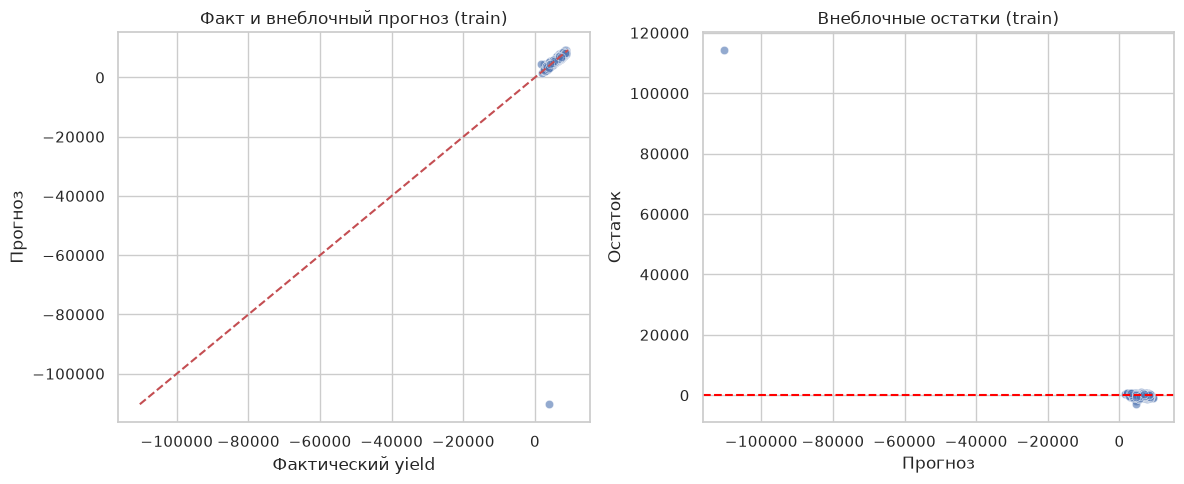

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(x=y_train, y=pred, alpha=0.6, ax=axes[0])
lo, hi = min(y_train.min(), pred.min()), max(y_train.max(), pred.max())
axes[0].plot([lo, hi], [lo, hi], "r--")
axes[0].set(
    xlabel="Фактический yield",
    ylabel="Прогноз",
    title="Факт и внеблочный прогноз (train)",
)
sns.scatterplot(x=pred, y=residuals, alpha=0.6, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Прогноз", ylabel="Остаток", title="Внеблочные остатки (train)")
plt.tight_layout()
plt.show()

In [38]:
linear = clone(models["Линейная регрессия"]).fit(X_train, y_train)
coefficients = pd.Series(
    linear.named_steps["linearregression"].coef_,
    index=feature_names,
    name="Коэффициент после стандартизации",
)
coefficients.sort_values().to_frame().round(2)

,Коэффициент после стандартизации
MaxOfUpperTRange,-71997.19
MinOfLowerTRange,-41763.84
MinOfUpperTRange,-40488.17
AverageRainingDays,-1415.01
clonesize,-681.16
andrena,103.64
honeybee,115.26
osmia,368.78
bumbles,409.39
RainingDays,617.49


### Распределение остатков

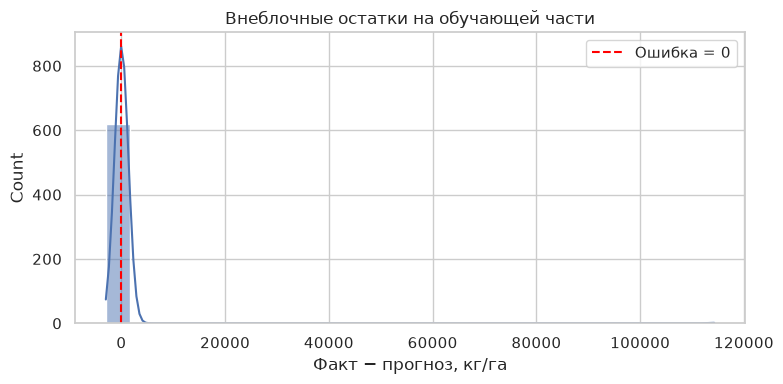

Средний остаток: 182.08 кг/га
Медианный остаток: 28.54 кг/га


In [39]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(residuals, bins=25, kde=True, ax=ax)
ax.axvline(0, color="red", linestyle="--", label="Ошибка = 0")
ax.set(title="Внеблочные остатки на обучающей части", xlabel="Факт − прогноз, кг/га")
ax.legend()
plt.tight_layout()
plt.show()
print("Средний остаток:", round(residuals.mean(), 2), "кг/га")
print("Медианный остаток:", round(residuals.median(), 2), "кг/га")

## 7. Регуляризация и подбор гиперпараметров

Полная линейная модель дала большие по модулю коэффициенты на связанных температурных признаках. Проверяем, помогает ли L2-регуляризация: `Ridge` штрафует сумму квадратов коэффициентов, а `alpha` задаёт силу штрафа. Полином второй степени проверяет, полезны ли квадраты и взаимодействия признаков. Фиксированные варианты с `alpha=1` сравниваем до подбора.

Пайплайн получает исходные входные столбцы, переводит температуру в °C и выбирает признаки. Для полиномов масштабируем исходные признаки, строим квадраты и взаимодействия и масштабируем полученные столбцы перед `Ridge`. Для линейного Ridge достаточно одного скейлера.

Внешние пять фолдов совпадают с предыдущим сравнением. На каждом внешнем обучающем блоке поиск выбирает степень (1 или 2) и `alpha` по MAE на четырёх внутренних фолдах. Затем лучший пайплайн переобучается на всём внешнем обучающем блоке и оценивается на внешнем проверочном. У каждого метода 26 кандидатов. Поиск по сетке перебирает 13 значений `alpha` для каждой степени, случайный поиск выбирает конфигурации и значения `alpha` из логарифмического распределения в том же диапазоне. Скейлеры обучаются заново на обучающей части каждого фолда. Отложенные 156 строк в эксперименте не используются.

In [40]:
def ridge_pipeline(polynomial=False):
    return Pipeline([
        ("inputs", model_input(feature_names)),
        ("scale_inputs", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False) if polynomial else "passthrough"),
        ("scale_poly", StandardScaler() if polynomial else "passthrough"),
        ("ridge", Ridge(alpha=1.0)),
    ])


inner_cv = KFold(n_splits=4, shuffle=True, random_state=42)
alpha_grid = np.logspace(-3, 3, 13)
param_grid = [
    {"poly": ["passthrough"], "scale_poly": ["passthrough"], "ridge__alpha": alpha_grid},
    {
        "poly": [PolynomialFeatures(degree=2, include_bias=False)],
        "scale_poly": [StandardScaler()],
        "ridge__alpha": alpha_grid,
    },
]
param_distributions = [
    {**params, "ridge__alpha": loguniform(1e-3, 1e3)} for params in param_grid
]

grid_name = "Ridge · GridSearchCV"
random_name = "Ridge · RandomizedSearchCV"
linear_name = "Линейная регрессия · 7 признаков"
ridge_name = "Ridge · alpha=1"
poly_name = "Ridge + полином · alpha=1"

regularization_models = {
    "Среднее (baseline)": DummyRegressor(strategy="mean"),
    linear_name: make_pipeline(model_input(reduced_features), StandardScaler(), LinearRegression()),
    ridge_name: ridge_pipeline(),
    poly_name: ridge_pipeline(polynomial=True),
    grid_name: GridSearchCV(
        ridge_pipeline(), param_grid, scoring="neg_mean_absolute_error", cv=inner_cv,
        error_score="raise",
    ),
    random_name: RandomizedSearchCV(
        ridge_pipeline(), param_distributions, n_iter=2 * len(alpha_grid),
        scoring="neg_mean_absolute_error", cv=inner_cv, random_state=42,
        error_score="raise",
    ),
}

In [41]:
outer_splits = list(cv.split(X_raw, y_train))
regularization_rows = []
case_predictions = []
case_idx = df_raw.index[df_raw["Row#"] == 776]

for name, estimator in regularization_models.items():
    evaluation = cross_validate(
        estimator, X_raw, y_train, cv=outer_splits,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
        return_estimator=True, error_score="raise",
    )

    for fold, (_, valid_idx) in enumerate(outer_splits, start=1):
        fitted = evaluation["estimator"][fold - 1]
        best_params = getattr(fitted, "best_params_", None)
        selected_pipeline = getattr(fitted, "best_estimator_", fitted)
        steps = getattr(selected_pipeline, "named_steps", {})
        ridge = steps.get("ridge")
        regularization_rows.append({
            "Модель": name,
            "Фолд": fold,
            "MAE, кг/га": -evaluation["test_mae"][fold - 1],
            "RMSE, кг/га": -evaluation["test_rmse"][fold - 1],
            "R²": evaluation["test_r2"][fold - 1],
            "Степень": 2 if isinstance(steps.get("poly"), PolynomialFeatures) else (1 if steps else None),
            "alpha": ridge.alpha if ridge is not None else None,
            "MAE внутренней CV, кг/га": -fitted.best_score_ if best_params else None,
        })

        if case_idx.isin(X_raw.index[valid_idx]).any():
            observed = y_train.loc[case_idx].iloc[0]
            forecast = fitted.predict(X_raw.loc[case_idx])[0]
            case_predictions.append({
                "Модель": name, "Фолд": fold, "Факт, кг/га": observed,
                "Прогноз, кг/га": forecast, "Абсолютная ошибка, кг/га": abs(observed - forecast),
            })

regularization_folds = pd.DataFrame(regularization_rows).set_index(["Модель", "Фолд"])
regularization_summary = regularization_folds.groupby(level="Модель", sort=False).agg(
    mean_mae=("MAE, кг/га", "mean"),
    std_mae=("MAE, кг/га", "std"),
    worst_mae=("MAE, кг/га", "max"),
    mean_rmse=("RMSE, кг/га", "mean"),
    mean_r2=("R²", "mean"),
)
regularization_summary.columns = [
    "Средняя MAE, кг/га", "Разброс MAE (SD), кг/га", "Худшая MAE, кг/га",
    "Средняя RMSE, кг/га", "Средний R²",
]
mae_column = "Средняя MAE, кг/га"
reference_mae = regularization_summary.loc[linear_name, mae_column]
regularization_summary["Снижение MAE к линейной, кг/га"] = (
    reference_mae - regularization_summary[mae_column]
)
regularization_summary.sort_values(mae_column).round(2)

,"Средняя MAE, кг/га","Разброс MAE (SD), кг/га","Худшая MAE, кг/га","Средняя RMSE, кг/га",Средний R²,"Снижение MAE к линейной, кг/га"
Модель,,,,,,
Ridge + полином · alpha=1,259.60,18.88,280.72,352.53,0.93,258.12
Ridge · RandomizedSearchCV,270.79,51.71,354.26,545.83,0.75,246.94
Ridge · GridSearchCV,281.14,63.56,379.75,616.57,0.69,236.59
Ridge · alpha=1,482.34,14.11,498.27,598.69,0.80,35.39
Линейная регрессия · 7 признаков,517.73,14.41,535.48,631.33,0.77,0.00
Среднее (baseline),1099.43,70.89,1190.32,1347.12,-0.03,-581.70


### Параметры по фолдам и проверка сценария 776

Таблица отделяет MAE внутреннего поиска от MAE внешней проверки. Прогноз для сценария 776 получен на его внешнем проверочном фолде.

In [42]:
print("MAE каждого варианта по внешним фолдам, кг/га:")
display(regularization_folds["MAE, кг/га"].unstack("Фолд").round(2))

search_folds = regularization_folds.loc[[grid_name, random_name]]
display(search_folds.round({"MAE, кг/га": 2, "RMSE, кг/га": 2, "R²": 3, "alpha": 5,
                            "MAE внутренней CV, кг/га": 2}))
print("Отдельная диагностика сценария Row# 776 на внешнем фолде:")
display(pd.DataFrame(case_predictions).set_index("Модель").round(2))

MAE каждого варианта по внешним фолдам, кг/га:


Фолд,1,2,3,4,5
Модель,,,,,
Ridge + полином · alpha=1,232.20,267.88,267.50,280.72,249.71
Ridge · GridSearchCV,214.37,258.70,379.75,303.17,249.71
Ridge · RandomizedSearchCV,215.00,257.54,354.26,276.56,250.59
Ridge · alpha=1,463.25,485.22,498.27,473.28,491.69
Линейная регрессия · 7 признаков,497.62,535.48,523.17,522.40,509.97
Среднее (baseline),994.35,1108.93,1120.41,1190.32,1083.12


MAE, кг/га  RMSE, кг/га     R²  Степень  \
Модель                     Фолд                                            
Ridge · GridSearchCV       1         214.37       320.49  0.933      2.0   
                           2         258.70       336.05  0.935      2.0   
                           3         379.75      1529.58 -0.198      2.0   
                           4         303.17       574.29  0.847      2.0   
                           5         249.71       322.44  0.930      2.0   
Ridge · RandomizedSearchCV 1         215.00       323.07  0.932      2.0   
                           2         257.54       334.09  0.936      2.0   
                           3         354.26      1388.36  0.013      2.0   
                           4         276.56       360.25  0.940      2.0   
                           5         250.59       323.36  0.930      2.0   

                                    alpha  MAE внутренней CV, кг/га  
Модель                     Фолд                                      
Ridge · GridSearchCV       1      0.01000                    264.60  
                           2     10.00000                    274.00  
                           3      0.01000                    238.47  
                           4      0.31623                    259.39  
                           5      1.00000                    260.50  
Ridge · RandomizedSearchCV 1      0.01578                    262.27  
                           2      8.04138                    269.23  
                           3      0.01578                    233.66  
                           4      1.40779                    263.91  
                           5      1.40779                    259.59

Отдельная диагностика сценария Row# 776 на внешнем фолде:


,Фолд,"Факт, кг/га","Прогноз, кг/га","Абсолютная ошибка, кг/га"
Модель,,,,
Среднее (baseline),3,3943.13,6049.18,2106.05
Линейная регрессия · 7 признаков,3,3943.13,3390.78,552.36
Ridge · alpha=1,3,3943.13,3038.76,904.37
Ridge + полином · alpha=1,3,3943.13,3144.11,799.02
Ridge · GridSearchCV,3,3943.13,5695.86,1752.72
Ridge · RandomizedSearchCV,3,3943.13,4053.12,109.99


In [43]:
best_search = regularization_summary.loc[[grid_name, random_name], mae_column].idxmin()
best_fixed = regularization_summary.loc[[ridge_name, poly_name], mae_column].idxmin()
fixed_mae = regularization_summary.loc[best_fixed, mae_column]
ridge_default_mae = regularization_summary.loc[ridge_name, mae_column]
poly_default_mae = regularization_summary.loc[poly_name, mae_column]

print(f"Линейный Ridge при alpha=1: {ridge_default_mae:.2f} кг/га; "
      f"Ridge с полиномом при alpha=1: {poly_default_mae:.2f} кг/га.")
for name in (grid_name, random_name):
    search_mae = regularization_summary.loc[name, mae_column]
    print(f"{name}: MAE {search_mae:.2f} кг/га; снижение к модели на 7 признаках "
          f"{reference_mae - search_mae:+.2f} кг/га, к лучшему Ridge с alpha=1 "
          f"{fixed_mae - search_mae:+.2f} кг/га.")
print(f"По средней внешней MAE лучший из двух методов подбора — {best_search}.")
best_model = regularization_summary[mae_column].idxmin()
best_mae = regularization_summary.loc[best_model, mae_column]
print(f"Кандидат с минимальной средней внешней MAE: {best_model}, {best_mae:.2f} кг/га.")


Линейный Ridge при alpha=1: 482.34 кг/га; Ridge с полиномом при alpha=1: 259.60 кг/га.
Ridge · GridSearchCV: MAE 281.14 кг/га; снижение к модели на 7 признаках +236.59 кг/га, к лучшему Ridge с alpha=1 -21.54 кг/га.
Ridge · RandomizedSearchCV: MAE 270.79 кг/га; снижение к модели на 7 признаках +246.94 кг/га, к лучшему Ridge с alpha=1 -11.19 кг/га.
По средней внешней MAE лучший из двух методов подбора — Ridge · RandomizedSearchCV.
Кандидат с минимальной средней внешней MAE: Ridge + полином · alpha=1, 259.60 кг/га.


В этом эксперименте Ridge с полиномом второй степени и фиксированным `alpha=1` снизил среднюю MAE с 517,73 до 259,60 кг/га. Случайный поиск получил меньшую среднюю MAE из двух методов поиска. Оба метода уступили фиксированному полиномиальному Ridge и дали больший разброс по внешним фолдам. Поэтому для дальнейшей проверки выбираем полиномиальный Ridge с `alpha=1`. Это предварительный выбор по пяти фолдам симуляционных данных.

На сценарии 776 у случайного поиска абсолютная ошибка около 110 кг/га, а у фиксированного полиномиального Ridge — 799 кг/га. Итоговый выбор основан на средней ошибке по всем фолдам.

## 8. Выводы и ограничения

- Анализ данных и все эксперименты выполнены на 621 симуляционном сценарии. 156 строк остаются отложенными в этой версии.
- Тесно связанные погодные признаки делают полную линейную регрессию чувствительной к нетипичным сочетаниям, как в сценарии 776. Суммарная плотность опылителей и температурный размах не улучшили среднюю MAE в первоначальном сравнении.
- Для дальнейшей проверки выбрали Ridge с полиномом второй степени и `alpha=1`. Средняя MAE на пяти фолдах — 259,60 кг/га, стандартное отклонение — 18,88 кг/га. Оба метода подбора уступили этому варианту. Для независимой финальной оценки нужны ранее не изученные данные, а для переноса в хозяйство — полевые наблюдения и проверка доступности признаков к концу цветения.
- Затраты на тару в разделе 5.6 рассчитаны для выбранных линейных моделей и условных тарифов. Выбор регуляризованной модели сделан по MAE.

## Вклад команды

- Павел Прудывус — разведочный анализ и подготовка данных.
- Антон Лебедев — тимлид, координация этапов проекта.
- Андрей Аргунов — коммуникация внутри команды.
- Константин Лапин — анализ влияния разбиения выборок на результаты.
- Владислав Лавров и Роман Квасной — обучение моделей и подбор гиперпараметров.